<a href="https://colab.research.google.com/github/Anishamalar/Logistic-bottleneck-and-route-analysis/blob/main/Logistic_bottleneck_and_route_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pandas


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv(
    "DataCoSupplyChainDataset.csv",
    encoding="latin1"
)

In [ ]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [ ]:
df.shape

(180519, 53)

In [ ]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [ ]:
pd.set_option("display.max_columns", None)

In [ ]:
df.head()

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [ ]:
df.isnull().sum()

,0
Type,0
Days for shipping (real),0
Days for shipment (scheduled),0
Benefit per order,0
Sales per customer,0
Delivery Status,0
Late_delivery_risk,0
Category Id,0
Category Name,0
Customer City,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  object 
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  object 
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  object 
 9   Customer City                  180519 non-null  object 
 10  Customer Country               180519 non-null  object 
 11  Customer Email                 180519 non-null  object 
 12  Customer Fname                

In [ ]:
df.describe()


,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Customer Zipcode,Department Id,Latitude,Longitude,Order Customer Id,Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Price,Product Status
count,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,24840.000000,180519.000000,180519.000000,0.0,180519.000000,180519.0
mean,3.497654,2.931847,21.974989,183.107609,0.548291,31.851451,6691.379495,35921.126914,5.443460,29.719955,-84.915675,6691.379495,36221.894903,692.509764,20.664741,0.101668,90260.000000,141.232550,0.120647,2.127638,203.772096,183.107609,21.974989,55426.132327,692.509764,31.851451,NaN,141.232550,0.0
std,1.623722,1.374449,104.433526,120.043670,0.497664,15.640064,4162.918106,37542.461122,1.629246,9.813646,21.433241,4162.918106,21045.379569,336.446807,21.800901,0.070415,52111.490959,139.732492,0.466796,1.453451,132.273077,120.043670,104.433526,31919.279101,336.446807,15.640064,NaN,139.732492,0.0
min,0.000000,0.000000,-4274.979980,7.490000,0.000000,2.000000,1.000000,603.000000,2.000000,-33.937553,-158.025986,1.000000,1.000000,19.000000,0.000000,0.000000,1.000000,9.990000,-2.750000,1.000000,9.990000,7.490000,-4274.979980,1040.000000,19.000000,2.000000,NaN,9.990000,0.0
25%,2.000000,2.000000,7.000000,104.379997,0.000000,18.000000,3258.500000,725.000000,4.000000,18.265432,-98.446312,3258.500000,18057.000000,403.000000,5.400000,0.040000,45130.500000,50.000000,0.080000,1.000000,119.980003,104.379997,7.000000,23464.000000,403.000000,18.000000,NaN,50.000000,0.0
50%,3.000000,4.000000,31.520000,163.990005,1.000000,29.000000,6457.000000,19380.000000,5.000000,33.144863,-76.847908,6457.000000,36140.000000,627.000000,14.000000,0.100000,90260.000000,59.990002,0.270000,1.000000,199.919998,163.990005,31.520000,59405.000000,627.000000,29.000000,NaN,59.990002,0.0
75%,5.000000,4.000000,64.800003,247.399994,1.000000,45.000000,9779.000000,78207.000000,7.000000,39.279617,-66.370583,9779.000000,54144.000000,1004.000000,29.990000,0.160000,135389.500000,199.990005,0.360000,3.000000,299.950012,247.399994,64.800003,90008.000000,1004.000000,45.000000,NaN,199.990005,0.0
max,6.000000,4.000000,911.799988,1939.989990,1.000000,76.000000,20757.000000,99205.000000,12.000000,48.781933,115.263077,20757.000000,77204.000000,1363.000000,500.000000,0.250000,180519.000000,1999.989990,0.500000,5.000000,1999.989990,1939.989990,911.799988,99301.000000,1363.000000,76.000000,NaN,1999.989990,0.0


In [ ]:
# Check Market and Order Region values

print("Unique Markets:")
print(df["Market"].unique())

print("\nNumber of Markets:")
print(df["Market"].nunique())

print("\nNumber of Order Regions:")
print(df["Order Region"].nunique())

print("\nMarket -> Order Region combinations:")
market_region = (
    df[["Market", "Order Region"]]
    .drop_duplicates()
    .sort_values(["Market", "Order Region"])
)

print(market_region.to_string(index=False))

Unique Markets:
['Pacific Asia' 'USCA' 'Africa' 'Europe' 'LATAM']

Number of Markets:
5

Number of Order Regions:
23

Market -> Order Region combinations:
      Market    Order Region
      Africa  Central Africa
      Africa     East Africa
      Africa    North Africa
      Africa Southern Africa
      Africa     West Africa
      Europe  Eastern Europe
      Europe Northern Europe
      Europe Southern Europe
      Europe  Western Europe
       LATAM       Caribbean
       LATAM Central America
       LATAM   South America
Pacific Asia    Central Asia
Pacific Asia    Eastern Asia
Pacific Asia         Oceania
Pacific Asia      South Asia
Pacific Asia  Southeast Asia
Pacific Asia       West Asia
        USCA          Canada
        USCA     East of USA
        USCA  South of  USA 
        USCA      US Center 
        USCA    West of USA 


In [ ]:
df.describe(include="object").T

,count,unique,top,freq
Type,180519,4,DEBIT,69295
Delivery Status,180519,4,Late delivery,98977
Category Name,180519,50,Cleats,24551
Customer City,180519,563,Caguas,66770
Customer Country,180519,2,EE. UU.,111146
Customer Email,180519,1,XXXXXXXXX,180519
Customer Fname,180519,782,Mary,65150
Customer Lname,180511,1109,Smith,64104
Customer Password,180519,1,XXXXXXXXX,180519
Customer Segment,180519,3,Consumer,93504


# Calculate delay above scheduled duration
route_performance["schedule_delay"] = (
    route_performance["avg_actual_shipping_days"]
    - route_performance["avg_scheduled_shipping_days"]
)

# Correlation between bottleneck score and actual delivery performance
score_correlations = route_performance[
    ["bottleneck_score",
     "avg_actual_shipping_days",
     "avg_scheduled_shipping_days",
     "schedule_delay",
     "avg_delay_risk"]
].corr()["bottleneck_score"]

print("Correlation with Bottleneck Score:")
print(score_correlations)

converting timestamp

1.   List item
2.   List item



In [ ]:
df["order date (DateOrders)"] = pd.to_datetime(
    df["order date (DateOrders)"]
)

df["shipping date (DateOrders)"] = pd.to_datetime(
    df["shipping date (DateOrders)"]
)

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   Type                           180519 non-null  object        
 1   Days for shipping (real)       180519 non-null  int64         
 2   Days for shipment (scheduled)  180519 non-null  int64         
 3   Benefit per order              180519 non-null  float64       
 4   Sales per customer             180519 non-null  float64       
 5   Delivery Status                180519 non-null  object        
 6   Late_delivery_risk             180519 non-null  int64         
 7   Category Id                    180519 non-null  int64         
 8   Category Name                  180519 non-null  object        
 9   Customer City                  180519 non-null  object        
 10  Customer Country               180519 non-null  object        
 11  

removing unnecessary columns

In [ ]:
df.drop(
    columns=[
        "Product Description",
        "Customer Email",
        "Customer Password"
    ],
    inplace=True
)

Categorizing the shipments based on their delivery status

In [ ]:
df["Delivery Status"].value_counts()

,count
Delivery Status,
Late delivery,98977
Advance shipping,41592
Shipping on time,32196
Shipping canceled,7754


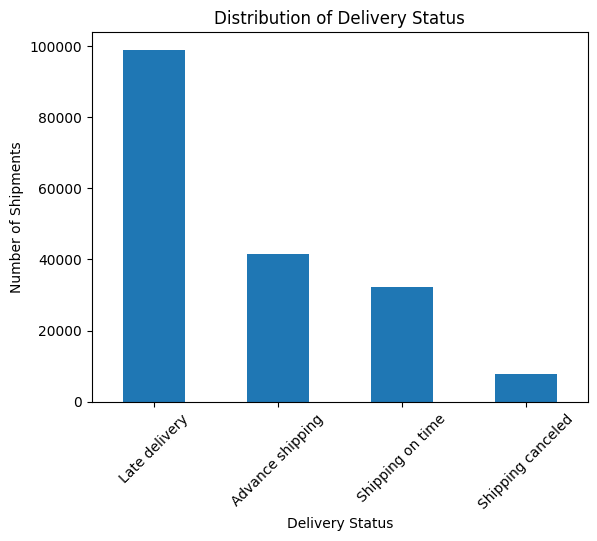

In [ ]:
import matplotlib.pyplot as plt

df["Delivery Status"].value_counts().plot(kind="bar")

plt.title("Distribution of Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")

plt.xticks(rotation=45)

plt.show()

delayed vs non-delayed shipments

In [ ]:
df["Late_delivery_risk"].value_counts()

,count
Late_delivery_risk,
1,98977
0,81542


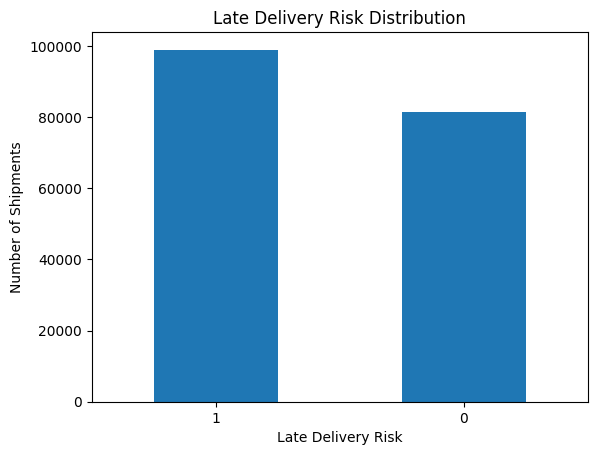

In [ ]:
df["Late_delivery_risk"].value_counts().plot(
    kind="bar"
)

plt.title("Late Delivery Risk Distribution")
plt.xlabel("Late Delivery Risk")
plt.ylabel("Number of Shipments")

plt.xticks(rotation=0)

plt.show()

location based shipping analysis

In [ ]:
df.groupby("Order Region")[
    "Days for shipping (real)"
].mean().sort_values(ascending=False)

,Days for shipping (real)
Order Region,
Central Africa,3.560525
West Africa,3.534091
Eastern Asia,3.527335
East Africa,3.514579
Central America,3.510462
Caribbean,3.507213
South America,3.505725
West of USA,3.504942
Northern Europe,3.502349


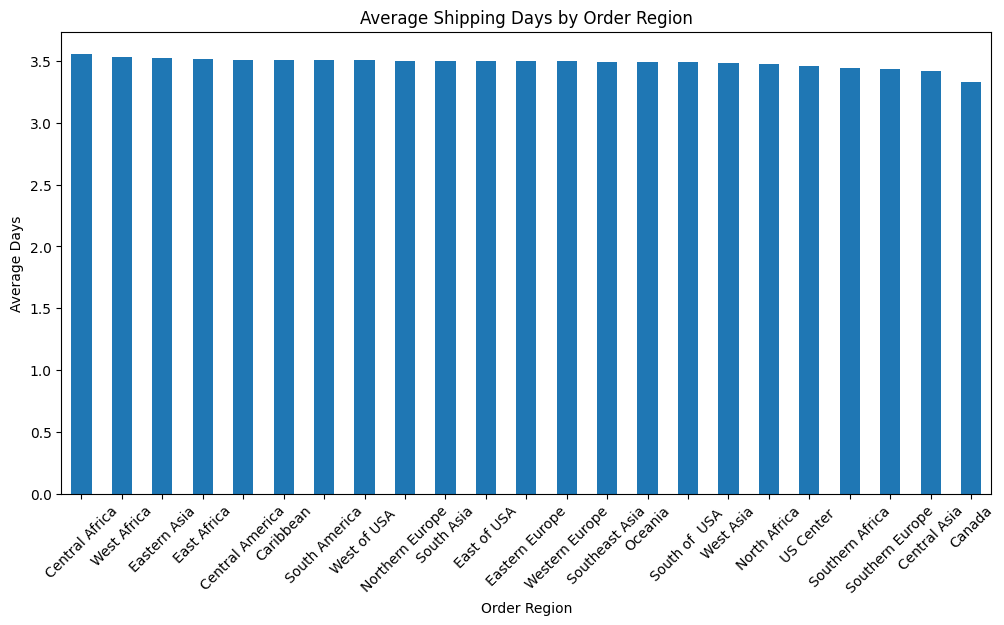

In [ ]:
df.groupby("Order Region")[
    "Days for shipping (real)"
].mean().sort_values(
    ascending=False
).plot(kind="bar", figsize=(12,6))

plt.title("Average Shipping Days by Order Region")
plt.xlabel("Order Region")
plt.ylabel("Average Days")

plt.xticks(rotation=45)

plt.show()

relation between shipping mode and delivery time

In [ ]:
df.groupby("Shipping Mode")[
    "Days for shipping (real)"
].mean().sort_values(ascending=False)

,Days for shipping (real)
Shipping Mode,
Standard Class,3.995907
Second Class,3.990828
First Class,2.000000
Same Day,0.478279


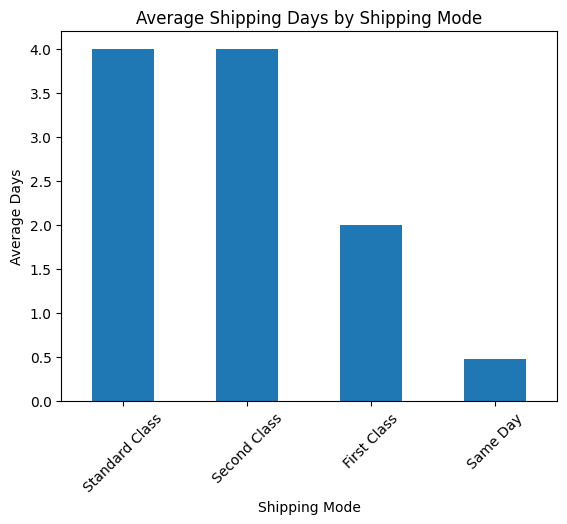

In [ ]:
df.groupby("Shipping Mode")[
    "Days for shipping (real)"
].mean().sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Average Shipping Days by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Days")

plt.xticks(rotation=45)

plt.show()

Shipping mode showed a clear relationship with delivery duration. Standard Class and Second Class shipments averaged approximately four days, while First Class averaged around two days and Same Day shipments remained below one day. This indicates that shipping mode is a strong predictor for ETA estimation.

In [ ]:
df.groupby("Order Region")[
    "Late_delivery_risk"
].mean().sort_values(ascending=False)

,Late_delivery_risk
Order Region,
Central Africa,0.579606
South Asia,0.562670
East Africa,0.559395
Western Europe,0.558486
South of USA,0.557726
Eastern Europe,0.556633
East of USA,0.556616
Southeast Asia,0.555299
Central Asia,0.553345


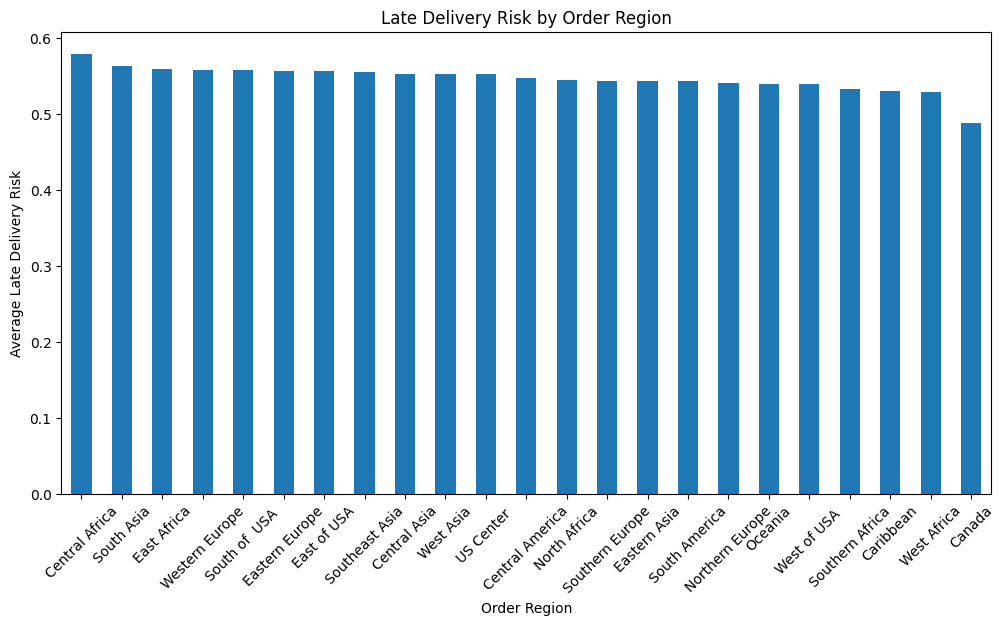

In [ ]:
df.groupby("Order Region")[
    "Late_delivery_risk"
].mean().sort_values(
    ascending=False
).plot(kind="bar", figsize=(12,6))

plt.title("Late Delivery Risk by Order Region")
plt.xlabel("Order Region")
plt.ylabel("Average Late Delivery Risk")

plt.xticks(rotation=45)

plt.show()

Regions may not differ strongly in average delivery duration, but they do differ more clearly in probability of delay.

In [ ]:
df.groupby("Days for shipment (scheduled)")[
    "Days for shipping (real)"
].mean()

,Days for shipping (real)
Days for shipment (scheduled),
0,0.478279
1,2.000000
2,3.990828
4,3.995907


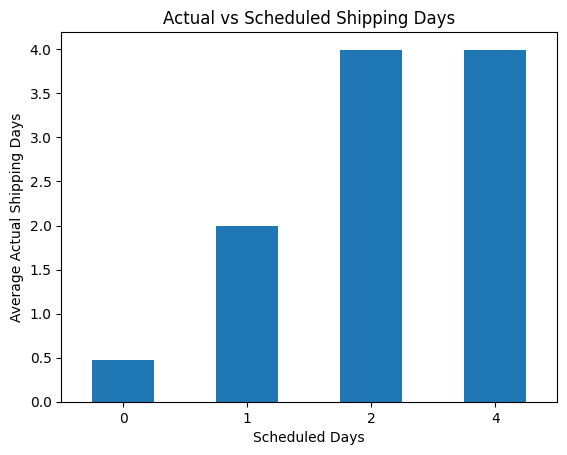

In [ ]:
df.groupby("Days for shipment (scheduled)")[
    "Days for shipping (real)"
].mean().plot(kind="bar")

plt.title("Actual vs Scheduled Shipping Days")
plt.xlabel("Scheduled Days")
plt.ylabel("Average Actual Shipping Days")

plt.xticks(rotation=0)

plt.show()

Scheduled delivery duration showed a strong positive relationship with actual delivery time. However, shipments scheduled for two days displayed average actual transit times close to four days, indicating operational delays and highlighting the need for predictive ETA modeling.

In [ ]:
df.groupby("Shipping Mode")[
    "Late_delivery_risk"
].mean().sort_values(ascending=False)

,Late_delivery_risk
Shipping Mode,
First Class,0.953225
Second Class,0.766328
Same Day,0.457430
Standard Class,0.380717


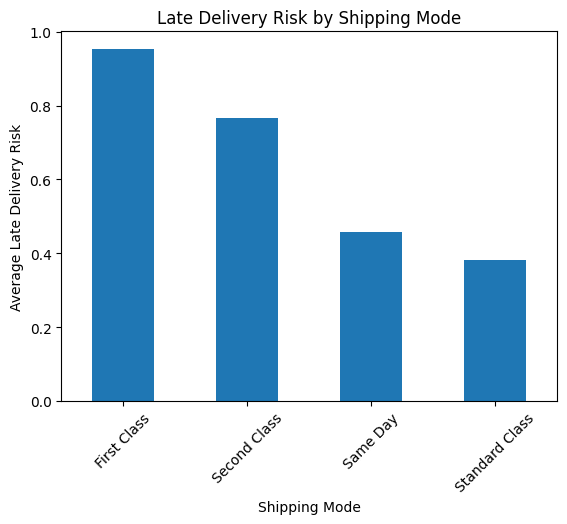

In [ ]:
df.groupby("Shipping Mode")[
    "Late_delivery_risk"
].mean().sort_values(
    ascending=False
).plot(kind="bar")

plt.title("Late Delivery Risk by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Average Late Delivery Risk")

plt.xticks(rotation=45)

plt.show()

Shipping mode demonstrated a strong relationship with delivery delays. First Class shipments showed the highest late-delivery risk, followed by Second Class, while Standard Class recorded the lowest. This suggests that faster delivery commitments may face tighter operational constraints, increasing the probability of delay.

In [ ]:
pd.crosstab(
    df["Shipping Mode"],
    df["Delivery Status"]
)

Delivery Status,Advance shipping,Late delivery,Shipping canceled,Shipping on time
Shipping Mode,,,,
First Class,0,26513,1301,0
Same Day,0,4454,444,4839
Second Class,0,26987,1410,6819
Standard Class,41592,41023,4599,20538


Cross-tabulation between shipping mode and delivery status revealed strong variation across shipment types. First Class and Second Class orders were predominantly labeled as late deliveries, whereas Standard Class showed a more balanced distribution across advance, on-time, and delayed deliveries. This indicates that shipping mode is a major operational factor influencing delivery outcomes.

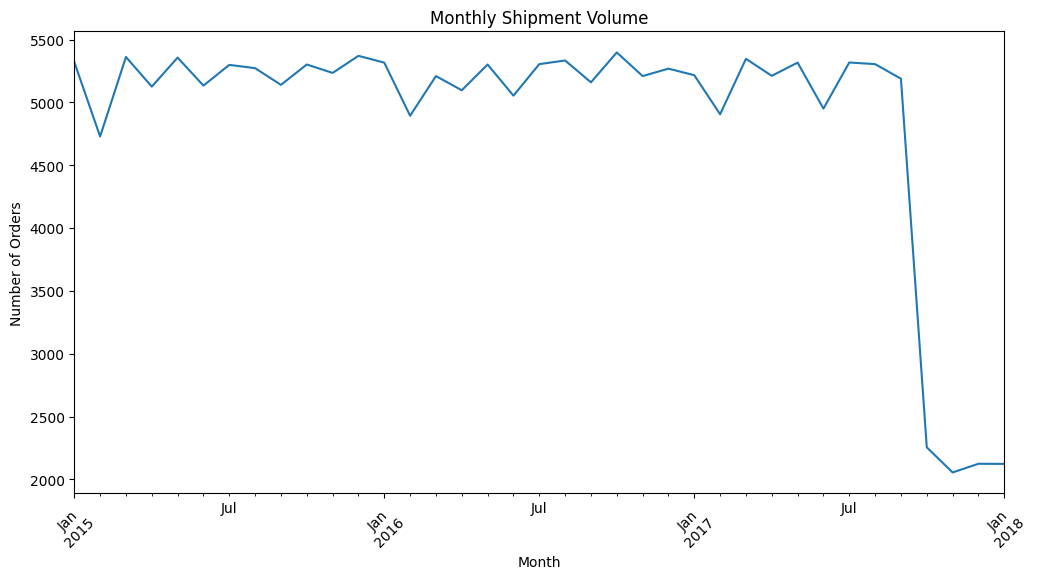

In [ ]:
df["order_month"] = df["order date (DateOrders)"].dt.to_period("M")

df["order_month"].value_counts().sort_index().plot(
    kind="line",
    figsize=(12,6)
)

plt.title("Monthly Shipment Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.show()

Route stage

checking delay pattern across time

In [ ]:
df["order_year"] = df["order date (DateOrders)"].dt.year
df["order_month_num"] = df["order date (DateOrders)"].dt.month
df["order_day"] = df["order date (DateOrders)"].dt.day
df["order_weekday"] = df["order date (DateOrders)"].dt.day_name()

In [ ]:
df["shipping_delay_days"] = (
    df["Days for shipping (real)"]
    - df["Days for shipment (scheduled)"]
)

In [ ]:
df[
    [
        "order date (DateOrders)",
        "order_year",
        "order_month",
        "order_day",
        "order_weekday",
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "shipping_delay_days"
    ]
].head()

,order date (DateOrders),order_year,order_month,order_day,order_weekday,Days for shipping (real),Days for shipment (scheduled),shipping_delay_days
0,2018-01-31 22:56:00,2018,2018-01,31,Wednesday,3,4,-1
1,2018-01-13 12:27:00,2018,2018-01,13,Saturday,5,4,1
2,2018-01-13 12:06:00,2018,2018-01,13,Saturday,4,4,0
3,2018-01-13 11:45:00,2018,2018-01,13,Saturday,3,4,-1
4,2018-01-13 11:24:00,2018,2018-01,13,Saturday,2,4,-2


In [ ]:
df["order_month"] = df["order date (DateOrders)"].dt.month

In [ ]:
df[
    [
        "order date (DateOrders)",
        "order_year",
        "order_month",
        "order_day",
        "order_weekday",
        "Days for shipping (real)",
        "Days for shipment (scheduled)",
        "shipping_delay_days"
    ]
].head()

,order date (DateOrders),order_year,order_month,order_day,order_weekday,Days for shipping (real),Days for shipment (scheduled),shipping_delay_days
0,2018-01-31 22:56:00,2018,1,31,Wednesday,3,4,-1
1,2018-01-13 12:27:00,2018,1,13,Saturday,5,4,1
2,2018-01-13 12:06:00,2018,1,13,Saturday,4,4,0
3,2018-01-13 11:45:00,2018,1,13,Saturday,3,4,-1
4,2018-01-13 11:24:00,2018,1,13,Saturday,2,4,-2


Analyzing based on market and route

In [ ]:
df["route"] = (
    df["Market"].astype(str)
    + " -> "
    + df["Order Region"].astype(str)
)

In [ ]:
df[["Market", "Order Region", "route"]].head()

,Market,Order Region,route
0,Pacific Asia,Southeast Asia,Pacific Asia -> Southeast Asia
1,Pacific Asia,South Asia,Pacific Asia -> South Asia
2,Pacific Asia,South Asia,Pacific Asia -> South Asia
3,Pacific Asia,Oceania,Pacific Asia -> Oceania
4,Pacific Asia,Oceania,Pacific Asia -> Oceania


In [ ]:
df["route"].value_counts().head(15)

,count
route,
LATAM -> Central America,28341
Europe -> Western Europe,27109
LATAM -> South America,14935
Pacific Asia -> Oceania,10148
Europe -> Northern Europe,9792
Pacific Asia -> Southeast Asia,9539
Europe -> Southern Europe,9431
LATAM -> Caribbean,8318
USCA -> West of USA,7993


In [ ]:
df.groupby("route")["Late_delivery_risk"].mean().sort_values(ascending=False).head(10)

,Late_delivery_risk
route,
Africa -> Central Africa,0.579606
Pacific Asia -> South Asia,0.562670
Africa -> East Africa,0.559395
Europe -> Western Europe,0.558486
USCA -> South of USA,0.557726
Europe -> Eastern Europe,0.556633
USCA -> East of USA,0.556616
Pacific Asia -> Southeast Asia,0.555299
Pacific Asia -> Central Asia,0.553345


Pacific asia- central asia is showing highest late delivery risk

In [ ]:
df.groupby("route").agg({
    "Late_delivery_risk": "mean",
    "Order Id": "count"
}).sort_values(
    by="Order Id",
    ascending=False
).head(10)

,Late_delivery_risk,Order Id
route,,
LATAM -> Central America,0.547546,28341
Europe -> Western Europe,0.558486,27109
LATAM -> South America,0.543087,14935
Pacific Asia -> Oceania,0.540205,10148
Europe -> Northern Europe,0.540441,9792
Pacific Asia -> Southeast Asia,0.555299,9539
Europe -> Southern Europe,0.543845,9431
LATAM -> Caribbean,0.530777,8318
USCA -> West of USA,0.539597,7993


more delayed in  busier routes but also less traffic routes

In [ ]:
df.groupby("route")[
    "Days for shipping (real)"
].mean().sort_values(
    ascending=False
).head(10)

,Days for shipping (real)
route,
Africa -> Central Africa,3.560525
Africa -> West Africa,3.534091
Pacific Asia -> Eastern Asia,3.527335
Africa -> East Africa,3.514579
LATAM -> Central America,3.510462
LATAM -> Caribbean,3.507213
LATAM -> South America,3.505725
USCA -> West of USA,3.504942
Europe -> Northern Europe,3.502349


In [ ]:
pd.crosstab(
    df["route"],
    df["Shipping Mode"]
).head(10)

Shipping Mode,First Class,Same Day,Second Class,Standard Class
route,,,,
Africa -> Central Africa,300,79,297,1001
Africa -> East Africa,280,98,362,1112
Africa -> North Africa,486,193,617,1936
Africa -> Southern Africa,198,75,150,734
Africa -> West Africa,463,223,738,2272
Europe -> Eastern Europe,658,178,772,2312
Europe -> Northern Europe,1418,517,1953,5904
Europe -> Southern Europe,1504,569,1698,5660
Europe -> Western Europe,4312,1495,5438,15864


shipping mode has a strong relation

categorizing shipment as delayed / not delayed or on time

In [ ]:
df["delivery_speed"] = df["shipping_delay_days"].apply(
    lambda x:
    "Early" if x < 0
    else "On Time" if x == 0
    else "Delayed"
)

In [ ]:
df["delivery_speed"].value_counts()

,count
delivery_speed,
Delayed,103400
Early,43366
On Time,33753


Train ETA regression and classification baselines

In [ ]:
df[
    [
        "Days for shipping (real)",
        "Late_delivery_risk"
    ]
].head()

,Days for shipping (real),Late_delivery_risk
0,3,0
1,5,1
2,4,0
3,3,0
4,2,0


specifying input output

In [ ]:
y_reg = df["Days for shipping (real)"]

y_cls = df["Late_delivery_risk"]

In [ ]:
features = [
    "Days for shipment (scheduled)",
    "Shipping Mode",
    "Market",
    "Order Region",
    "order_year",
    "order_month",
    "order_day",
    "order_weekday",
    "route"
]

X = df[features]

Train Test split

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X,
    y_reg,
    test_size=0.2,
    random_state=42
)

In [ ]:
_, _, y_cls_train, y_cls_test = train_test_split(
    X,
    y_cls,
    test_size=0.2,
    random_state=42
)

In [ ]:
X_train_encoded = pd.get_dummies(X_train)

X_test_encoded = pd.get_dummies(X_test)

X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
X.isnull().sum()

,0
Days for shipment (scheduled),0
Shipping Mode,0
Market,0
Order Region,0
order_year,0
order_month,0
order_day,0
order_weekday,0
route,0


In [ ]:
df[
    X.isnull().any(axis=1)
][
    [
        "Market",
        "Order Region",
        "Shipping Mode",
        "order date (DateOrders)",
        "order_year",
        "order_month",
        "order_day",
        "order_weekday",
        "route"
    ]
]

,Market,Order Region,Shipping Mode,order date (DateOrders),order_year,order_month,order_day,order_weekday,route


In [ ]:
X = X.dropna()

y_reg = y_reg.loc[X.index]

y_cls = y_cls.loc[X.index]

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
reg_model = LinearRegression()

reg_model.fit(
    X_train_encoded,
    y_reg_train
)

LinearRegression()

removing a broken row

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_reg_train, y_reg_test = train_test_split(
    X,
    y_reg,
    test_size=0.2,
    random_state=42
)

In [ ]:
X_train_encoded = pd.get_dummies(X_train)

X_test_encoded = pd.get_dummies(X_test)

In [ ]:
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

In [ ]:
reg_model = LinearRegression()

reg_model.fit(
    X_train_encoded,
    y_reg_train
)

LinearRegression()

Test data prediction

In [ ]:
y_reg_pred = reg_model.predict(
    X_test_encoded
)

In [ ]:
y_reg_pred[:5]

array([3.98483075, 2.00030186, 3.99628044, 4.01547055, 3.96314205])

MAE Calculation

In [ ]:
from sklearn.metrics import mean_absolute_error

In [ ]:
mae = mean_absolute_error(
    y_reg_test,
    y_reg_pred
)

print("MAE:", mae)

MAE: 0.9848205667410688


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Mean baseline using only the training data
mean_baseline_value = y_reg_train.mean()

y_mean_pred = np.full(
    len(y_reg_test),
    mean_baseline_value
)

mean_mae = mean_absolute_error(y_reg_test, y_mean_pred)
mean_rmse = np.sqrt(mean_squared_error(y_reg_test, y_mean_pred))
mean_r2 = r2_score(y_reg_test, y_mean_pred)

print("Mean Baseline")
print("Mean prediction:", mean_baseline_value)
print("MAE:", mean_mae)
print("RMSE:", mean_rmse)
print("R²:", mean_r2)

Mean Baseline
Mean prediction: 3.4975660423086246
MAE: 1.4240646196392532
RMSE: 1.6235739058898002
R²: -7.335099816430102e-08


In [ ]:
# Scheduled-shipping baseline
y_scheduled_pred = df.loc[X_test.index, "Days for shipment (scheduled)"]

scheduled_mae = mean_absolute_error(y_reg_test, y_scheduled_pred)
scheduled_rmse = np.sqrt(mean_squared_error(y_reg_test, y_scheduled_pred))
scheduled_r2 = r2_score(y_reg_test, y_scheduled_pred)

print("Scheduled Shipping Baseline")
print("MAE:", scheduled_mae)
print("RMSE:", scheduled_rmse)
print("R²:", scheduled_r2)

Scheduled Shipping Baseline
MAE: 1.2822124972302238
RMSE: 1.589376918665186
R²: 0.0416818577251179


In [ ]:
# Linear Regression additional evaluation metrics

linear_rmse = np.sqrt(
    mean_squared_error(y_reg_test, y_reg_pred)
)

linear_r2 = r2_score(
    y_reg_test, y_reg_pred
)

print("Linear Regression")
print("MAE:", mean_absolute_error(y_reg_test, y_reg_pred))
print("RMSE:", linear_rmse)
print("R²:", linear_r2)

Linear Regression
MAE: 0.9848205667410688
RMSE: 1.2663220699585338
R²: 0.3916629626129411


In [ ]:
# Regression model and baseline comparison

regression_comparison = pd.DataFrame({
    "Method": [
        "Mean Baseline",
        "Scheduled Shipping Baseline",
        "Linear Regression"
    ],
    "MAE (days)": [
        mean_mae,
        scheduled_mae,
        mean_absolute_error(y_reg_test, y_reg_pred)
    ],
    "RMSE (days)": [
        mean_rmse,
        scheduled_rmse,
        linear_rmse
    ],
    "R²": [
        mean_r2,
        scheduled_r2,
        linear_r2
    ]
})

regression_comparison

,Method,MAE (days),RMSE (days),R²
0,Mean Baseline,1.424065,1.623574,-7.335100e-08
1,Scheduled Shipping Baseline,1.282212,1.589377,4.168186e-02
2,Linear Regression,0.984821,1.266322,3.916630e-01


#7

In [ ]:
from sklearn.metrics import median_absolute_error

median_ae = median_absolute_error(
    y_reg_test,
    y_reg_pred
)

print("Median Absolute Error:", median_ae)

Median Absolute Error: 0.9964437413431961


In [ ]:
# Calculate residuals
residuals = y_reg_test - y_reg_pred

print("Residual summary:")
print(residuals.describe())

Residual summary:
count    36104.000000
mean        -0.000206
std          1.266340
min         -2.130958
25%         -0.990984
50%          0.002973
75%          1.002861
max          2.177753
Name: Days for shipping (real), dtype: float64


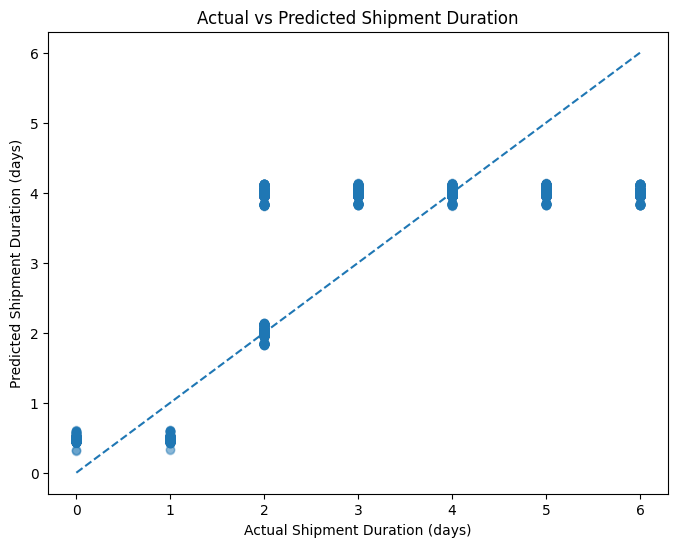

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_test,
    y_reg_pred,
    alpha=0.3
)

# Perfect prediction reference line
min_value = min(y_reg_test.min(), y_reg_pred.min())
max_value = max(y_reg_test.max(), y_reg_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Shipment Duration (days)")
plt.ylabel("Predicted Shipment Duration (days)")
plt.title("Actual vs Predicted Shipment Duration")
plt.show()

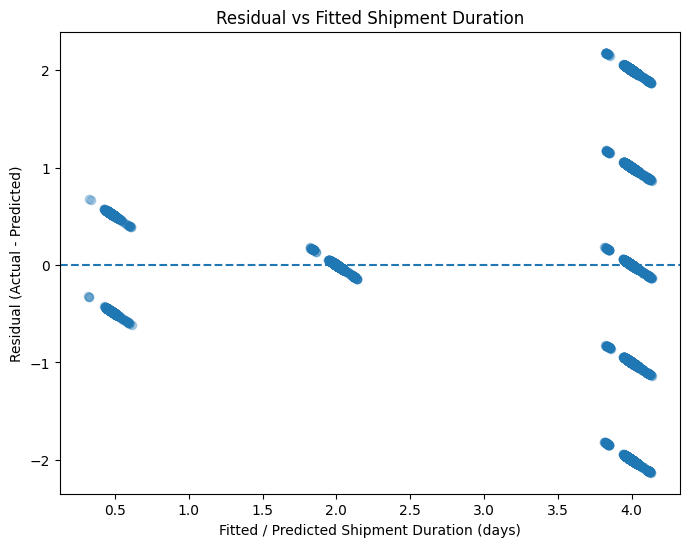

In [ ]:
# Residual vs Fitted Values

plt.figure(figsize=(8, 6))

plt.scatter(
    y_reg_pred,
    residuals,
    alpha=0.3
)

# Zero-residual reference line
plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Fitted / Predicted Shipment Duration (days)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual vs Fitted Shipment Duration")
plt.show()

In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan
import statsmodels.api as sm

# Breusch-Pagan test using fitted values
fitted_values = pd.Series(
    y_reg_pred,
    index=y_reg_test.index,
    name="Fitted"
)

X_bp = sm.add_constant(fitted_values)

bp_test = het_breuschpagan(
    residuals,
    X_bp
)

bp_labels = [
    "LM Statistic",
    "LM-Test p-value",
    "F-Statistic",
    "F-Test p-value"
]

print("Breusch-Pagan Test")
for label, value in zip(bp_labels, bp_test):
    print(f"{label}: {value}")

Breusch-Pagan Test
LM Statistic: 6858.523992861866
LM-Test p-value: 0.0
F-Statistic: 8466.48668429483
F-Test p-value: 0.0


In [ ]:
# Identify observations with unusually large absolute residuals

abs_residuals = residuals.abs()

outlier_threshold = 2

outlier_mask = abs_residuals > outlier_threshold

print("Number of observations with |residual| > 2 days:",
      outlier_mask.sum())

print("Percentage of observations:",
      round(outlier_mask.mean() * 100, 2), "%")

print("\nLargest absolute residuals:")
print(
    abs_residuals
    .sort_values(ascending=False)
    .head(10)
)

Number of observations with |residual| > 2 days: 5694
Percentage of observations: 15.77 %

Largest absolute residuals:
10693     2.177753
140121    2.177072
98899     2.177072
47079     2.176709
63648     2.175266
41785     2.174426
150234    2.174260
18490     2.172879
98988     2.171485
21701     2.171485
Name: Days for shipping (real), dtype: float64


In [ ]:
# Show variables currently available that may relate to the regression data
[name for name in dir() if name.startswith("X") or name.startswith("x")]

['X',
 'X_bp',
 'X_classification',
 'X_test',
 'X_test_encoded',
 'X_train',
 'X_train_encoded',
 'X_vif']

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Use the encoded training predictors from the regression model
X_vif = X_train_encoded.copy()

# Make sure all variables are numeric
X_vif = X_vif.astype(float)

# Calculate VIF
vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

# Sort from highest to lowest VIF
vif_results = vif_results.sort_values(
    by="VIF",
    ascending=False
)

vif_results

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


,Feature,VIF
0,Days for shipment (scheduled),inf
5,Shipping Mode_Same Day,inf
50,route_Europe -> Southern Europe,inf
4,Shipping Mode_First Class,inf
7,Shipping Mode_Standard Class,inf
...,...,...
61,route_USCA -> Canada,inf
65,route_USCA -> West of USA,inf
2,order_month,1.688741
1,order_year,1.039209


In [ ]:
# Summarise VIF results

print("Total predictors:", len(vif_results))

print("Infinite VIF:",
      np.isinf(vif_results["VIF"]).sum())

print("VIF > 10:",
      (vif_results["VIF"] > 10).sum())

print("VIF > 5:",
      (vif_results["VIF"] > 5).sum())

print("\nHighest finite VIF values:")
print(
    vif_results[
        np.isfinite(vif_results["VIF"])
    ].sort_values("VIF", ascending=False).head(10)
)

Total predictors: 66
Infinite VIF: 63
VIF > 10: 63
VIF > 5: 63

Highest finite VIF values:
       Feature       VIF
2  order_month  1.688741
1   order_year  1.039209
3    order_day  1.005620


In [ ]:
# MAE by Shipping Mode

mode_results = pd.DataFrame({
    "Shipping Mode": df.loc[y_reg_test.index, "Shipping Mode"],
    "Actual": y_reg_test,
    "Predicted": y_reg_pred
})

mode_mae = (
    mode_results
    .groupby("Shipping Mode")
    .apply(
        lambda x: mean_absolute_error(
            x["Actual"],
            x["Predicted"]
        )
    )
    .reset_index(name="MAE (days)")
    .sort_values("MAE (days)")
)

mode_mae

/tmp/ipykernel_2067/1905715044.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Shipping Mode,MAE (days)
0,First Class,0.015820
1,Same Day,0.499727
2,Second Class,1.204731
3,Standard Class,1.205599


In [ ]:
# MAE by Market

market_results = pd.DataFrame({
    "Market": df.loc[y_reg_test.index, "Market"],
    "Actual": y_reg_test,
    "Predicted": y_reg_pred
})

market_mae = (
    market_results
    .groupby("Market")
    .apply(
        lambda x: mean_absolute_error(
            x["Actual"],
            x["Predicted"]
        )
    )
    .reset_index(name="MAE (days)")
    .sort_values("MAE (days)")
)

market_mae

/tmp/ipykernel_2067/3259296626.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Market,MAE (days)
0,Africa,0.971026
2,LATAM,0.976407
3,Pacific Asia,0.986609
1,Europe,0.987822
4,USCA,0.998688


In [ ]:
# MAE by Order Region

region_results = pd.DataFrame({
    "Order Region": df.loc[y_reg_test.index, "Order Region"],
    "Actual": y_reg_test,
    "Predicted": y_reg_pred
})

region_mae = (
    region_results
    .groupby("Order Region")
    .apply(
        lambda x: mean_absolute_error(
            x["Actual"],
            x["Predicted"]
        )
    )
    .reset_index(name="MAE (days)")
    .sort_values("MAE (days)")
)

region_mae

/tmp/ipykernel_2067/478029900.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Order Region,MAE (days)
9,North Africa,0.933993
16,Southern Africa,0.940423
17,Southern Europe,0.956326
6,East of USA,0.957507
1,Caribbean,0.961903
4,Central Asia,0.962055
18,US Center,0.963177
19,West Africa,0.965156
3,Central America,0.971692
20,West Asia,0.974774


In [ ]:
# Test-set sample size by Shipping Mode

shipping_mode_counts = (
    df.loc[y_reg_test.index, "Shipping Mode"]
    .value_counts()
    .rename_axis("Shipping Mode")
    .reset_index(name="Number of Test Shipments")
)

shipping_mode_counts

,Shipping Mode,Number of Test Shipments
0,Standard Class,21586
1,Second Class,7026
2,First Class,5531
3,Same Day,1961


In [ ]:
# Retrieve the actual shipping timestamp for the test observations
shipping_dates_test = pd.to_datetime(
    df.loc[X_test.index, "shipping date (DateOrders)"]
)

shipping_dates_test.head()

,shipping date (DateOrders)
80120,2016-04-06 21:05:00
19670,2017-06-11 18:43:00
114887,2015-01-04 14:32:00
120110,2017-01-15 01:46:00
56658,2017-04-08 07:15:00


In [ ]:
# Calculate predicted ETA
predicted_eta = shipping_dates_test + pd.to_timedelta(
    y_reg_pred, unit="D"
)

predicted_eta.head()

,0
80120,2016-04-10 20:43:09.377153980
19670,2017-06-13 18:43:26.080547520
114887,2015-01-08 14:26:38.630200144
120110,2017-01-19 02:08:16.655559873
56658,2017-04-12 06:21:55.473060461


In [ ]:
# Create final ETA prediction results
eta_results = pd.DataFrame({
    "Shipping Date": shipping_dates_test,
    "Actual Shipping Duration (days)": y_reg_test,
    "Predicted Shipping Duration (days)": y_reg_pred,
    "Predicted ETA": predicted_eta
})

# Round predicted duration for presentation
eta_results["Predicted Shipping Duration (days)"] = (
    eta_results["Predicted Shipping Duration (days)"].round(2)
)

# Display first 10 results
eta_results.head(10)

,Shipping Date,Actual Shipping Duration (days),Predicted Shipping Duration (days),Predicted ETA
80120,2016-04-06 21:05:00,5,3.98,2016-04-10 20:43:09.377153980
19670,2017-06-11 18:43:00,2,2.00,2017-06-13 18:43:26.080547520
114887,2015-01-04 14:32:00,2,4.00,2015-01-08 14:26:38.630200144
120110,2017-01-15 01:46:00,5,4.02,2017-01-19 02:08:16.655559873
56658,2017-04-08 07:15:00,2,3.96,2017-04-12 06:21:55.473060461
99465,2016-08-12 23:21:00,5,3.97,2016-08-16 22:44:14.250129218
40749,2015-09-06 10:52:00,6,3.98,2015-09-10 10:23:34.070678411
22688,2016-12-05 14:04:00,2,4.00,2016-12-09 14:10:03.621570111
154389,2017-02-21 20:59:00,6,4.00,2017-02-25 20:57:58.507978560
47301,2017-03-24 20:03:00,4,4.01,2017-03-28 20:20:04.081686486


Classification baseline

In [ ]:
classification_features = [
    "Days for shipment (scheduled)",
    "Shipping Mode",
    "Market",
    "Order Region",
    "order_year",
    "order_month",
    "order_day",
    "order_weekday",
    "route"
]

X_classification = df[classification_features]

In [ ]:
X_train, X_test, y_cls_train, y_cls_test = train_test_split(
    X_classification,
    y_cls,
    test_size=0.2,
    random_state=42
)

In [ ]:
X_train.isnull().sum()

,0
Days for shipment (scheduled),0
Shipping Mode,0
Market,0
Order Region,0
order_year,0
order_month,0
order_day,0
order_weekday,0
route,0


In [ ]:
X_test.isnull().sum()

,0
Days for shipment (scheduled),0
Shipping Mode,0
Market,0
Order Region,0
order_year,0
order_month,0
order_day,0
order_weekday,0
route,0


In [ ]:
X_train_encoded = pd.get_dummies(X_train)

X_test_encoded = pd.get_dummies(X_test)

In [ ]:
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

Logistic regression

In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
cls_model = LogisticRegression(
    max_iter=1000
)

cls_model.fit(
    X_train_encoded,
    y_cls_train
)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000)

In [ ]:
from sklearn.linear_model import LogisticRegression

cls_model = LogisticRegression(
    max_iter=3000
)

cls_model.fit(
    X_train_encoded,
    y_cls_train
)

LogisticRegression(max_iter=3000)

Predicting on test data

In [ ]:
y_cls_pred = cls_model.predict(
    X_test_encoded
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

# Classification performance metrics

accuracy = accuracy_score(
    y_cls_test,
    y_cls_pred
)

precision = precision_score(
    y_cls_test,
    y_cls_pred
)

recall = recall_score(
    y_cls_test,
    y_cls_pred
)

f1 = f1_score(
    y_cls_test,
    y_cls_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_cls_test,
    y_cls_pred
)

y_cls_prob = cls_model.predict_proba(
    X_test_encoded
)[:, 1]

roc_auc = roc_auc_score(
    y_cls_test,
    y_cls_prob
)

pr_auc = average_precision_score(
    y_cls_test,
    y_cls_prob
)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)
print("ROC-AUC:", roc_auc)
print("PR-AUC:", pr_auc)
print("Balanced Accuracy:", balanced_accuracy)

Accuracy: 0.6916962109461555
Precision: 0.8449291514090113
Recall: 0.5361418396726777
F1-score: 0.6560153280385673
ROC-AUC: 0.725554111770498
PR-AUC: 0.7936933875558629
Balanced Accuracy: 0.7083419690789954


In [ ]:
y_cls_pred[:10]

array([0, 1, 0, 0, 0, 0, 0, 0, 0, 0])

Confusion matrix

In [ ]:
from sklearn.metrics import confusion_matrix

confusion_matrix(
    y_cls_test,
    y_cls_pred
)

array([[14359,  1948],
       [ 9183, 10614]])

sequence or graph-based logistics models

In [ ]:
import networkx as nx

Decision tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    X_train_encoded,
    y_cls_train
)
y_dt_pred = dt_model.predict(
    X_test_encoded
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score
)

dt_accuracy = accuracy_score(
    y_cls_test,
    y_dt_pred
)

dt_precision = precision_score(
    y_cls_test,
    y_dt_pred
)

dt_recall = recall_score(
    y_cls_test,
    y_dt_pred
)

dt_f1 = f1_score(
    y_cls_test,
    y_dt_pred
)

dt_roc_auc = roc_auc_score(
    y_cls_test,
    dt_model.predict_proba(X_test_encoded)[:, 1]
)

dt_pr_auc = average_precision_score(
    y_cls_test,
    dt_model.predict_proba(X_test_encoded)[:, 1]
)

dt_balanced_accuracy = balanced_accuracy_score(
    y_cls_test,
    y_dt_pred
)

print("Decision Tree")
print("Accuracy:", dt_accuracy)
print("Precision:", dt_precision)
print("Recall:", dt_recall)
print("F1-score:", dt_f1)
print("ROC-AUC:", dt_roc_auc)
print("PR-AUC:", dt_pr_auc)
print("Balanced Accuracy:", dt_balanced_accuracy)

Decision Tree
Accuracy: 0.7167626855750056
Precision: 0.7926374365559836
Recall: 0.6547456685356368
F1-score: 0.7171230982019364
ROC-AUC: 0.7986136476008454
PR-AUC: 0.847796130878259
Balanced Accuracy: 0.7233990806650711


Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(
    X_train_encoded,
    y_cls_train
)
y_rf_pred = rf_model.predict(
    X_test_encoded
)
rf_accuracy = accuracy_score(
    y_cls_test,
    y_rf_pred
)

rf_precision = precision_score(
    y_cls_test,
    y_rf_pred
)

rf_recall = recall_score(
    y_cls_test,
    y_rf_pred
)

rf_f1 = f1_score(
    y_cls_test,
    y_rf_pred
)

rf_roc_auc = roc_auc_score(
    y_cls_test,
    rf_model.predict_proba(X_test_encoded)[:, 1]
)

rf_pr_auc = average_precision_score(
    y_cls_test,
    rf_model.predict_proba(X_test_encoded)[:, 1]
)

rf_balanced_accuracy = balanced_accuracy_score(
    y_cls_test,
    y_rf_pred
)

print("Random Forest")
print("Accuracy:", rf_accuracy)
print("Precision:", rf_precision)
print("Recall:", rf_recall)
print("F1-score:", rf_f1)
print("ROC-AUC:", rf_roc_auc)
print("PR-AUC:", rf_pr_auc)
print("Balanced Accuracy:", rf_balanced_accuracy)

Random Forest
Accuracy: 0.7180921781520053
Precision: 0.7838970544832065
Recall: 0.6708087083901602
F1-score: 0.7229571560781752
ROC-AUC: 0.799753047178788
PR-AUC: 0.852711759110674
Balanced Accuracy: 0.7231519472532759


11

In [ ]:
rf_delay_probability = rf_model.predict_proba(X_test_encoded)[:, 1]

print("Number of predicted probabilities:", len(rf_delay_probability))
print("Number of test observations:", len(X_test_encoded))

Number of predicted probabilities: 36104
Number of test observations: 36104


In [ ]:
# Create a copy of the test-set rows
test_results = X_test.copy()

# Add the Random Forest predicted probability of late delivery
test_results["predicted_delay_probability"] = rf_delay_probability

print(test_results.shape)
test_results[["predicted_delay_probability"]].head()

(36104, 10)


,predicted_delay_probability
80120,0.167098
19670,1.000000
114887,0.390927
120110,0.852889
56658,0.000000


In [ ]:
print(test_results.index[:10])
print(df.loc[test_results.index, ["Market", "Order Region"]].head(10))

Index([80120, 19670, 114887, 120110, 56658, 99465, 40749, 22688, 154389,
       47301],
      dtype='int64')
        Market     Order Region
80120     USCA     West of USA 
19670    LATAM  Central America
114887   LATAM  Central America
120110  Africa  Southern Africa
56658    LATAM        Caribbean
99465     USCA       US Center 
40749   Europe  Southern Europe
22688   Africa      East Africa
154389   LATAM  Central America
47301    LATAM  Central America


In [ ]:
# Add Market and Order Region to the test results
test_results["Market"] = df.loc[test_results.index, "Market"]
test_results["Order Region"] = df.loc[test_results.index, "Order Region"]

# Aggregate predicted delay probabilities by Market–Order Region
route_predicted_delay = (
    test_results
    .groupby(["Market", "Order Region"])
    .agg(
        shipment_count=("predicted_delay_probability", "size"),
        predicted_delay_probability=("predicted_delay_probability", "mean")
    )
    .reset_index()
)

# Calculate predicted delayed-shipment exposure
route_predicted_delay["predicted_delay_exposure"] = (
    route_predicted_delay["shipment_count"]
    * route_predicted_delay["predicted_delay_probability"]
)

# Show the highest-scoring relationships
route_predicted_delay.sort_values(
    "predicted_delay_exposure",
    ascending=False
).head(10)

,Market,Order Region,shipment_count,predicted_delay_probability,predicted_delay_exposure
10,LATAM,Central America,5614,0.550656,3091.382490
8,Europe,Western Europe,5493,0.562302,3088.724899
11,LATAM,South America,3005,0.540492,1624.177503
6,Europe,Northern Europe,2036,0.533743,1086.700781
14,Pacific Asia,Oceania,2006,0.541497,1086.242718
7,Europe,Southern Europe,1886,0.546727,1031.126596
16,Pacific Asia,Southeast Asia,1833,0.550780,1009.579693
22,USCA,West of USA,1658,0.534574,886.323683
15,Pacific Asia,South Asia,1556,0.565377,879.725906
9,LATAM,Caribbean,1627,0.526005,855.810117


In [ ]:
# Recreate the original observed-risk route analysis
route_analysis = (
    df.groupby(["Market", "Order Region"])
      .agg(
          shipment_count=("Delivery Status", "size"),
          avg_delay_risk=("Late_delivery_risk", "mean")
      )
      .reset_index()
)

# Original bottleneck score
route_analysis["bottleneck_score"] = (
    route_analysis["shipment_count"] *
    route_analysis["avg_delay_risk"]
)

# Compare original score with Random Forest predicted exposure
comparison = route_analysis[
    ["Market", "Order Region", "shipment_count",
     "avg_delay_risk", "bottleneck_score"]
].merge(
    route_predicted_delay[
        ["Market", "Order Region",
         "predicted_delay_probability",
         "predicted_delay_exposure"]
    ],
    on=["Market", "Order Region"],
    how="inner"
)

comparison.sort_values(
    "predicted_delay_exposure",
    ascending=False
).head(10)

,Market,Order Region,shipment_count,avg_delay_risk,bottleneck_score,predicted_delay_probability,predicted_delay_exposure
10,LATAM,Central America,28341,0.547546,15518.0,0.550656,3091.382490
8,Europe,Western Europe,27109,0.558486,15140.0,0.562302,3088.724899
11,LATAM,South America,14935,0.543087,8111.0,0.540492,1624.177503
6,Europe,Northern Europe,9792,0.540441,5292.0,0.533743,1086.700781
14,Pacific Asia,Oceania,10148,0.540205,5482.0,0.541497,1086.242718
7,Europe,Southern Europe,9431,0.543845,5129.0,0.546727,1031.126596
16,Pacific Asia,Southeast Asia,9539,0.555299,5297.0,0.550780,1009.579693
22,USCA,West of USA,7993,0.539597,4313.0,0.534574,886.323683
15,Pacific Asia,South Asia,7731,0.562670,4350.0,0.565377,879.725906
9,LATAM,Caribbean,8318,0.530777,4415.0,0.526005,855.810117


In [ ]:
# Build the original observed-risk score using ONLY the test observations

test_results["observed_late_risk"] = df.loc[
    test_results.index, "Late_delivery_risk"
]

test_route_comparison = (
    test_results
    .groupby(["Market", "Order Region"])
    .agg(
        shipment_count=("predicted_delay_probability", "size"),
        observed_late_risk=("observed_late_risk", "mean"),
        predicted_late_risk=("predicted_delay_probability", "mean")
    )
    .reset_index()
)

# Original score, calculated on the same test set
test_route_comparison["observed_risk_exposure"] = (
    test_route_comparison["shipment_count"]
    * test_route_comparison["observed_late_risk"]
)

# Model-based score
test_route_comparison["predicted_risk_exposure"] = (
    test_route_comparison["shipment_count"]
    * test_route_comparison["predicted_late_risk"]
)

# Show the top 10 according to the model-based score
test_route_comparison.sort_values(
    "predicted_risk_exposure",
    ascending=False
).head(10)

,Market,Order Region,shipment_count,observed_late_risk,predicted_late_risk,observed_risk_exposure,predicted_risk_exposure
10,LATAM,Central America,5614,0.550944,0.550656,3093.0,3091.382490
8,Europe,Western Europe,5493,0.558893,0.562302,3070.0,3088.724899
11,LATAM,South America,3005,0.549750,0.540492,1652.0,1624.177503
6,Europe,Northern Europe,2036,0.523084,0.533743,1065.0,1086.700781
14,Pacific Asia,Oceania,2006,0.545364,0.541497,1094.0,1086.242718
7,Europe,Southern Europe,1886,0.545599,0.546727,1029.0,1031.126596
16,Pacific Asia,Southeast Asia,1833,0.551555,0.550780,1011.0,1009.579693
22,USCA,West of USA,1658,0.520507,0.534574,863.0,886.323683
15,Pacific Asia,South Asia,1556,0.568766,0.565377,885.0,879.725906
9,LATAM,Caribbean,1627,0.539029,0.526005,877.0,855.810117


In [ ]:
route_validation = test_route_comparison[
    ["observed_late_risk", "predicted_late_risk"]
].corr()

print("Correlation between observed and predicted route-level late-delivery risk:")
print(route_validation)

Correlation between observed and predicted route-level late-delivery risk:
                     observed_late_risk  predicted_late_risk
observed_late_risk             1.000000             0.592814
predicted_late_risk            0.592814             1.000000


In [ ]:
# Model-based route-level predicted delay exposure
model_route_score = (
    test_results
    .groupby(["Market", "Order Region"])
    ["predicted_delay_probability"]
    .sum()
    .reset_index(name="model_delay_exposure")
)

# Rank the relationships
model_route_score = model_route_score.sort_values(
    "model_delay_exposure",
    ascending=False
)

model_route_score.head(10)

,Market,Order Region,model_delay_exposure
10,LATAM,Central America,3091.382490
8,Europe,Western Europe,3088.724899
11,LATAM,South America,1624.177503
6,Europe,Northern Europe,1086.700781
14,Pacific Asia,Oceania,1086.242718
7,Europe,Southern Europe,1031.126596
16,Pacific Asia,Southeast Asia,1009.579693
22,USCA,West of USA,886.323683
15,Pacific Asia,South Asia,879.725906
9,LATAM,Caribbean,855.810117


In [ ]:
# Merge the Random Forest route-level predictions
# into the existing test-set route analysis

final_route_analysis = test_route_comparison.merge(
    model_route_score,
    on=["Market", "Order Region"],
    how="left"
)

# Display the integrated route analysis
final_route_analysis = final_route_analysis.sort_values(
    "model_delay_exposure",
    ascending=False
)

final_route_analysis.head(10)

,Market,Order Region,shipment_count,observed_late_risk,predicted_late_risk,observed_risk_exposure,predicted_risk_exposure,model_delay_exposure
10,LATAM,Central America,5614,0.550944,0.550656,3093.0,3091.382490,3091.382490
8,Europe,Western Europe,5493,0.558893,0.562302,3070.0,3088.724899,3088.724899
11,LATAM,South America,3005,0.549750,0.540492,1652.0,1624.177503,1624.177503
6,Europe,Northern Europe,2036,0.523084,0.533743,1065.0,1086.700781,1086.700781
14,Pacific Asia,Oceania,2006,0.545364,0.541497,1094.0,1086.242718,1086.242718
7,Europe,Southern Europe,1886,0.545599,0.546727,1029.0,1031.126596,1031.126596
16,Pacific Asia,Southeast Asia,1833,0.551555,0.550780,1011.0,1009.579693,1009.579693
22,USCA,West of USA,1658,0.520507,0.534574,863.0,886.323683,886.323683
15,Pacific Asia,South Asia,1556,0.568766,0.565377,885.0,879.725906,879.725906
9,LATAM,Caribbean,1627,0.539029,0.526005,877.0,855.810117,855.810117


In [ ]:
# Create the final integrated route analysis
final_route_analysis = final_route_analysis.drop(
    columns=["model_delay_exposure"]
)

final_route_analysis = final_route_analysis.rename(
    columns={
        "predicted_risk_exposure": "model_based_bottleneck_indicator"
    }
)

final_route_analysis.head(10)

,Market,Order Region,shipment_count,observed_late_risk,predicted_late_risk,observed_risk_exposure,model_based_bottleneck_indicator
10,LATAM,Central America,5614,0.550944,0.550656,3093.0,3091.382490
8,Europe,Western Europe,5493,0.558893,0.562302,3070.0,3088.724899
11,LATAM,South America,3005,0.549750,0.540492,1652.0,1624.177503
6,Europe,Northern Europe,2036,0.523084,0.533743,1065.0,1086.700781
14,Pacific Asia,Oceania,2006,0.545364,0.541497,1094.0,1086.242718
7,Europe,Southern Europe,1886,0.545599,0.546727,1029.0,1031.126596
16,Pacific Asia,Southeast Asia,1833,0.551555,0.550780,1011.0,1009.579693
22,USCA,West of USA,1658,0.520507,0.534574,863.0,886.323683
15,Pacific Asia,South Asia,1556,0.568766,0.565377,885.0,879.725906
9,LATAM,Caribbean,1627,0.539029,0.526005,877.0,855.810117


In [ ]:
# Create the final model-integrated bottleneck ranking

final_bottleneck_analysis = (
    final_route_analysis[
        ["Market", "Order Region",
         "shipment_count",
         "predicted_late_risk",
         "model_based_bottleneck_indicator"]
    ]
    .sort_values(
        "model_based_bottleneck_indicator",
        ascending=False
    )
    .reset_index(drop=True)
)

final_bottleneck_analysis.head(10)

,Market,Order Region,shipment_count,predicted_late_risk,model_based_bottleneck_indicator
0,LATAM,Central America,5614,0.550656,3091.382490
1,Europe,Western Europe,5493,0.562302,3088.724899
2,LATAM,South America,3005,0.540492,1624.177503
3,Europe,Northern Europe,2036,0.533743,1086.700781
4,Pacific Asia,Oceania,2006,0.541497,1086.242718
5,Europe,Southern Europe,1886,0.546727,1031.126596
6,Pacific Asia,Southeast Asia,1833,0.550780,1009.579693
7,USCA,West of USA,1658,0.534574,886.323683
8,Pacific Asia,South Asia,1556,0.565377,879.725906
9,LATAM,Caribbean,1627,0.526005,855.810117


In [ ]:
# Final validation of the model-based bottleneck indicator

# 1. Check that there are no missing values
print("Missing values:")
print(final_bottleneck_analysis.isna().sum())

# 2. Check that all route scores are non-negative
print("\nNegative model-based indicators:")
print(
    (final_bottleneck_analysis["model_based_bottleneck_indicator"] < 0).sum()
)

# 3. Check the number of Market–Order Region relationships
print("\nNumber of route relationships:")
print(len(final_bottleneck_analysis))

# 4. Show final ranking
print("\nTop 10 model-based bottleneck indicators:")
print(final_bottleneck_analysis.head(10))

Missing values:
Market                              0
Order Region                        0
shipment_count                      0
predicted_late_risk                 0
model_based_bottleneck_indicator    0
dtype: int64

Negative model-based indicators:
0

Number of route relationships:
23

Top 10 model-based bottleneck indicators:
         Market     Order Region  shipment_count  predicted_late_risk  \
0         LATAM  Central America            5614             0.550656   
1        Europe   Western Europe            5493             0.562302   
2         LATAM    South America            3005             0.540492   
3        Europe  Northern Europe            2036             0.533743   
4  Pacific Asia          Oceania            2006             0.541497   
5        Europe  Southern Europe            1886             0.546727   
6  Pacific Asia   Southeast Asia            1833             0.550780   
7          USCA     West of USA             1658             0.534574   
8  Pacific

In [ ]:
# Combine the existing observed bottleneck indicator
# with the Random Forest model-based indicator

route_integrated_analysis = route_analysis[
    ["Market", "Order Region", "shipment_count",
     "avg_delay_risk", "bottleneck_score"]
].merge(
    final_bottleneck_analysis[
        ["Market", "Order Region",
         "predicted_late_risk",
         "model_based_bottleneck_indicator"]
    ],
    on=["Market", "Order Region"],
    how="inner"
)

# Rename columns for clarity
route_integrated_analysis = route_integrated_analysis.rename(
    columns={
        "avg_delay_risk": "observed_delay_risk",
        "bottleneck_score": "observed_bottleneck_indicator",
        "predicted_late_risk": "model_predicted_delay_risk"
    }
)

# Sort by the model-based indicator
route_integrated_analysis = route_integrated_analysis.sort_values(
    "model_based_bottleneck_indicator",
    ascending=False
).reset_index(drop=True)

route_integrated_analysis.head(10)

,Market,Order Region,shipment_count,observed_delay_risk,observed_bottleneck_indicator,model_predicted_delay_risk,model_based_bottleneck_indicator
0,LATAM,Central America,28341,0.547546,15518.0,0.550656,3091.382490
1,Europe,Western Europe,27109,0.558486,15140.0,0.562302,3088.724899
2,LATAM,South America,14935,0.543087,8111.0,0.540492,1624.177503
3,Europe,Northern Europe,9792,0.540441,5292.0,0.533743,1086.700781
4,Pacific Asia,Oceania,10148,0.540205,5482.0,0.541497,1086.242718
5,Europe,Southern Europe,9431,0.543845,5129.0,0.546727,1031.126596
6,Pacific Asia,Southeast Asia,9539,0.555299,5297.0,0.550780,1009.579693
7,USCA,West of USA,7993,0.539597,4313.0,0.534574,886.323683
8,Pacific Asia,South Asia,7731,0.562670,4350.0,0.565377,879.725906
9,LATAM,Caribbean,8318,0.530777,4415.0,0.526005,855.810117


Gradient boosting

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier
gb_model = GradientBoostingClassifier(
    random_state=42
)

gb_model.fit(
    X_train_encoded,
    y_cls_train
)
y_gb_pred = gb_model.predict(
    X_test_encoded
)
gb_accuracy = accuracy_score(
    y_cls_test,
    y_gb_pred
)

gb_precision = precision_score(
    y_cls_test,
    y_gb_pred
)

gb_recall = recall_score(
    y_cls_test,
    y_gb_pred
)

gb_f1 = f1_score(
    y_cls_test,
    y_gb_pred
)

gb_roc_auc = roc_auc_score(
    y_cls_test,
    gb_model.predict_proba(X_test_encoded)[:, 1]
)

gb_pr_auc = average_precision_score(
    y_cls_test,
    gb_model.predict_proba(X_test_encoded)[:, 1]
)

gb_balanced_accuracy = balanced_accuracy_score(
    y_cls_test,
    y_gb_pred
)

print("Gradient Boosting")
print("Accuracy:", gb_accuracy)
print("Precision:", gb_precision)
print("Recall:", gb_recall)
print("F1-score:", gb_f1)
print("ROC-AUC:", gb_roc_auc)
print("PR-AUC:", gb_pr_auc)
print("Balanced Accuracy:", gb_balanced_accuracy)

Gradient Boosting
Accuracy: 0.6922778639485929
Precision: 0.841819469583694
Recall: 0.5403343941001162
F1-score: 0.6581959143490032
ROC-AUC: 0.7314286320620479
PR-AUC: 0.8021633951123481
Balanced Accuracy: 0.7085372221926349


In [ ]:
comparison_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Accuracy": [
        0.6916962109461555,
        dt_accuracy,
        rf_accuracy,
        gb_accuracy
    ],
    "Precision": [
        0.8449291514090113,
        dt_precision,
        rf_precision,
        gb_precision
    ],
    "Recall": [
        0.5361418396726777,
        dt_recall,
        rf_recall,
        gb_recall
    ],
    "F1-score": [
        0.6560153280385673,
        dt_f1,
        rf_f1,
        gb_f1
    ],
    "ROC-AUC": [
        0.725554111770498,
        dt_roc_auc,
        rf_roc_auc,
        gb_roc_auc
    ],
    "PR-AUC": [
        0.7936933875558629,
        dt_pr_auc,
        rf_pr_auc,
        gb_pr_auc
    ],
    "Balanced Accuracy": [
        0.7083419690789954,
        dt_balanced_accuracy,
        rf_balanced_accuracy,
        gb_balanced_accuracy
    ]
})

comparison_df

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Balanced Accuracy
0,Logistic Regression,0.691696,0.844929,0.536142,0.656015,0.725554,0.793693,0.708342
1,Decision Tree,0.716763,0.792637,0.654746,0.717123,0.798614,0.847796,0.723399
2,Random Forest,0.718092,0.783897,0.670809,0.722957,0.799753,0.852712,0.723152
3,Gradient Boosting,0.692278,0.841819,0.540334,0.658196,0.731429,0.802163,0.708537


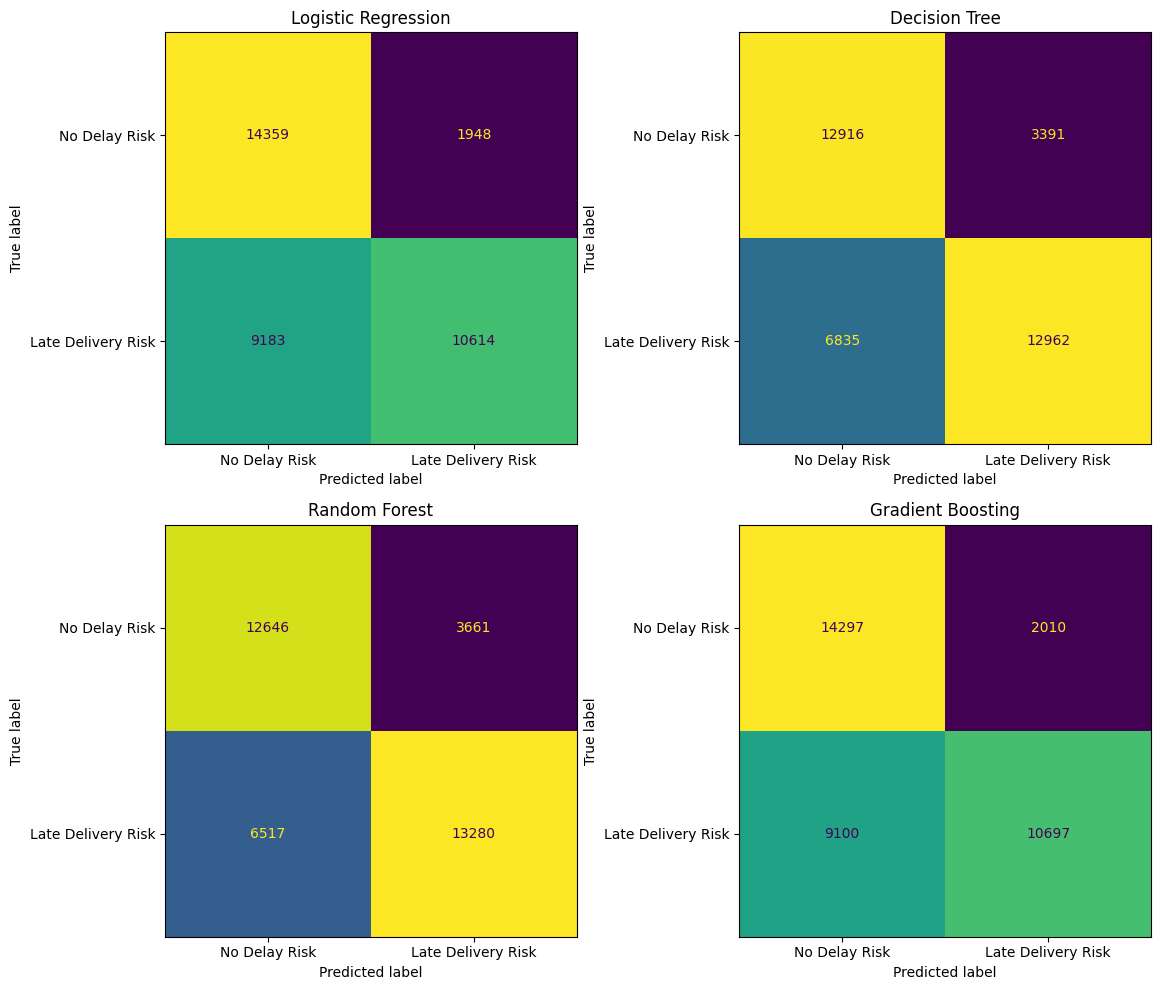

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Store model predictions
model_predictions = {
    "Logistic Regression": y_cls_pred,
    "Decision Tree": y_dt_pred,
    "Random Forest": y_rf_pred,
    "Gradient Boosting": y_gb_pred
}

# Create one figure with four confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (model_name, predictions) in zip(axes.ravel(), model_predictions.items()):

    cm = confusion_matrix(y_cls_test, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Delay Risk", "Late Delivery Risk"]
    )

    disp.plot(
        ax=ax,
        values_format="d",
        colorbar=False
    )

    ax.set_title(model_name)

plt.tight_layout()
plt.show()

Creating a graph from routes

In [ ]:
G = nx.from_pandas_edgelist(
    df,
    source="Market",
    target="Order Region",
    create_using=nx.DiGraph()
)

In [ ]:
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 28
Number of edges: 23


In [ ]:
route_counts = (
    df.groupby(["Market", "Order Region"])
      .size()
      .reset_index(name="weight")
)

route_counts.head()

,Market,Order Region,weight
0,Africa,Central Africa,1677
1,Africa,East Africa,1852
2,Africa,North Africa,3232
3,Africa,Southern Africa,1157
4,Africa,West Africa,3696


In [ ]:
G_weighted = nx.from_pandas_edgelist(
    route_counts,
    source="Market",
    target="Order Region",
    edge_attr="weight",
    create_using=nx.DiGraph()
)

In [ ]:
degree_centrality = nx.degree_centrality(G_weighted)

degree_df = (
    pd.DataFrame(
        degree_centrality.items(),
        columns=["Node", "Degree Centrality"]
    )
    .sort_values("Degree Centrality", ascending=False)
)

degree_df.head(10)

,Node,Degree Centrality
15,Pacific Asia,0.222222
0,Africa,0.185185
22,USCA,0.185185
6,Europe,0.148148
11,LATAM,0.111111
2,East Africa,0.037037
3,North Africa,0.037037
4,Southern Africa,0.037037
7,Eastern Europe,0.037037
8,Northern Europe,0.037037


In [ ]:
route_analysis = (
    df.groupby("route")
      .agg(
          shipment_count=("Order Id", "count"),
          avg_delay_risk=("Late_delivery_risk", "mean"),
          avg_shipping_days=("Days for shipping (real)", "mean")
      )
      .reset_index()
)

route_analysis.head()

,route,shipment_count,avg_delay_risk,avg_shipping_days
0,Africa -> Central Africa,1677,0.579606,3.560525
1,Africa -> East Africa,1852,0.559395,3.514579
2,Africa -> North Africa,3232,0.545173,3.480507
3,Africa -> Southern Africa,1157,0.533276,3.446845
4,Africa -> West Africa,3696,0.528409,3.534091


In [ ]:
route_analysis.sort_values(
    by="avg_delay_risk",
    ascending=False
).head(10)

,route,shipment_count,avg_delay_risk,avg_shipping_days
0,Africa -> Central Africa,1677,0.579606,3.560525
15,Pacific Asia -> South Asia,7731,0.562670,3.502005
1,Africa -> East Africa,1852,0.559395,3.514579
8,Europe -> Western Europe,27109,0.558486,3.498432
20,USCA -> South of USA,4045,0.557726,3.492707
5,Europe -> Eastern Europe,3920,0.556633,3.500765
19,USCA -> East of USA,6915,0.556616,3.500940
16,Pacific Asia -> Southeast Asia,9539,0.555299,3.496698
12,Pacific Asia -> Central Asia,553,0.553345,3.417722
17,Pacific Asia -> West Asia,6009,0.552837,3.486770


Africa → Central Africa has the highest delay risk, but only 1,677 shipments.
Europe → Western Europe has a slightly lower delay risk, but 27,109 shipments.

In [ ]:
route_analysis["bottleneck_score"] = (
    route_analysis["shipment_count"] *
    route_analysis["avg_delay_risk"]
)

route_analysis.sort_values(
    by="bottleneck_score",
    ascending=False
).head(10)

,route,shipment_count,avg_delay_risk,avg_shipping_days,bottleneck_score
10,LATAM -> Central America,28341,0.547546,3.510462,15518.0
8,Europe -> Western Europe,27109,0.558486,3.498432,15140.0
11,LATAM -> South America,14935,0.543087,3.505725,8111.0
14,Pacific Asia -> Oceania,10148,0.540205,3.496354,5482.0
16,Pacific Asia -> Southeast Asia,9539,0.555299,3.496698,5297.0
6,Europe -> Northern Europe,9792,0.540441,3.502349,5292.0
7,Europe -> Southern Europe,9431,0.543845,3.435797,5129.0
9,LATAM -> Caribbean,8318,0.530777,3.507213,4415.0
15,Pacific Asia -> South Asia,7731,0.562670,3.502005,4350.0
22,USCA -> West of USA,7993,0.539597,3.504942,4313.0


bottleneck score = Shipment Count × Average Delay Risk

visualizing top bottleneck routes

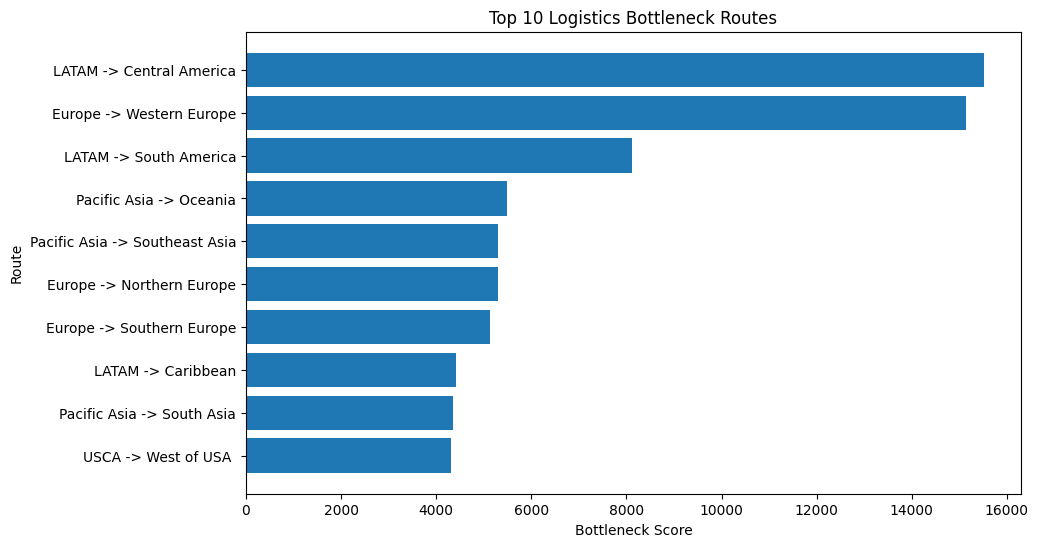

In [ ]:
import matplotlib.pyplot as plt

top_routes = route_analysis.sort_values(
    by="bottleneck_score",
    ascending=False
).head(10)

plt.figure(figsize=(10,6))

plt.barh(
    top_routes["route"],
    top_routes["bottleneck_score"]
)

plt.xlabel("Bottleneck Score")
plt.ylabel("Route")
plt.title("Top 10 Logistics Bottleneck Routes")

plt.gca().invert_yaxis()

plt.show()

Step - 4

In [ ]:
df = df.merge(
    route_analysis[["route", "bottleneck_score"]],
    on="route",
    how="left"
)

df[["route", "bottleneck_score"]].head()

,route,bottleneck_score
0,Pacific Asia -> Southeast Asia,5297.0
1,Pacific Asia -> South Asia,4350.0
2,Pacific Asia -> South Asia,4350.0
3,Pacific Asia -> Oceania,5482.0
4,Pacific Asia -> Oceania,5482.0


In [ ]:
df.groupby("route").agg(
    bottleneck_score=("bottleneck_score", "first"),
    delay_rate=("Late_delivery_risk", "mean")
).sort_values(
    by="bottleneck_score",
    ascending=False
).head(10)

,bottleneck_score,delay_rate
route,,
LATAM -> Central America,15518.0,0.547546
Europe -> Western Europe,15140.0,0.558486
LATAM -> South America,8111.0,0.543087
Pacific Asia -> Oceania,5482.0,0.540205
Pacific Asia -> Southeast Asia,5297.0,0.555299
Europe -> Northern Europe,5292.0,0.540441
Europe -> Southern Europe,5129.0,0.543845
LATAM -> Caribbean,4415.0,0.530777
Pacific Asia -> South Asia,4350.0,0.562670


LATAM → Central America has the highest bottleneck score because it combines very high shipment volume with a high delay rate.
Pacific Asia → South Asia has an even higher delay rate (0.5627), but it carries fewer shipments, so its bottleneck score is lower.

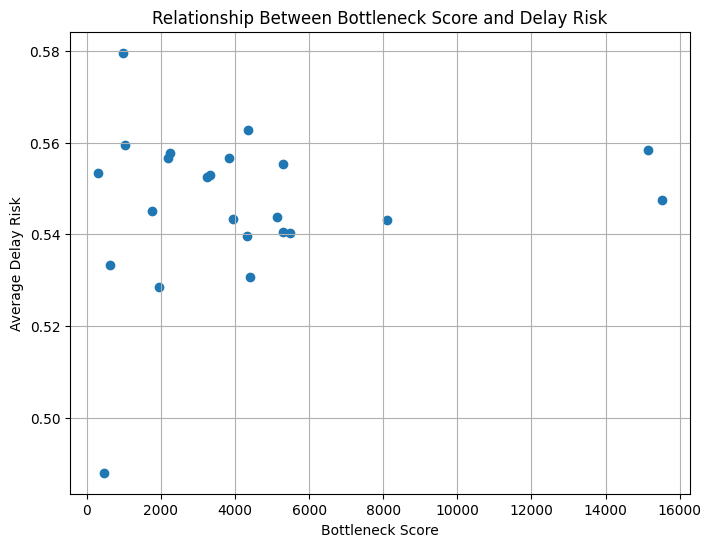

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    route_analysis["bottleneck_score"],
    route_analysis["avg_delay_risk"]
)

plt.xlabel("Bottleneck Score")
plt.ylabel("Average Delay Risk")
plt.title("Relationship Between Bottleneck Score and Delay Risk")

plt.grid(True)

plt.show()

The dataset did not contain detailed shipment event stages (e.g., warehouse, customs, distribution center). Therefore, bottleneck detection was performed at the route level using graph-based logistics analysis rather than at individual shipment stages.

Step-5

In [ ]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression",
        "Graph-based Bottleneck Analysis"
    ],
    "Task": [
        "ETA Prediction",
        "Delay Classification",
        "Route Bottleneck Detection"
    ],
    "Metric": [
        "MAE",
        "Accuracy",
        "Bottleneck Score"
    ],
    "Result": [
        0.959,
        0.7197,
        "Top bottleneck: LATAM -> Central America"
    ]
})

model_results

,Model,Task,Metric,Result
0,Linear Regression,ETA Prediction,MAE,0.959
1,Logistic Regression,Delay Classification,Accuracy,0.7197
2,Graph-based Bottleneck Analysis,Route Bottleneck Detection,Bottleneck Score,Top bottleneck: LATAM -> Central America


In [ ]:
top_bottlenecks = route_analysis.sort_values(
    by="bottleneck_score",
    ascending=False
).head(10)

top_bottlenecks

,route,shipment_count,avg_delay_risk,avg_shipping_days,bottleneck_score
10,LATAM -> Central America,28341,0.547546,3.510462,15518.0
8,Europe -> Western Europe,27109,0.558486,3.498432,15140.0
11,LATAM -> South America,14935,0.543087,3.505725,8111.0
14,Pacific Asia -> Oceania,10148,0.540205,3.496354,5482.0
16,Pacific Asia -> Southeast Asia,9539,0.555299,3.496698,5297.0
6,Europe -> Northern Europe,9792,0.540441,3.502349,5292.0
7,Europe -> Southern Europe,9431,0.543845,3.435797,5129.0
9,LATAM -> Caribbean,8318,0.530777,3.507213,4415.0
15,Pacific Asia -> South Asia,7731,0.562670,3.502005,4350.0
22,USCA -> West of USA,7993,0.539597,3.504942,4313.0


In [ ]:
# Structural degree measures
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())
total_degree = dict(G.degree())

degree_summary = pd.DataFrame({
    "Node": list(G.nodes()),
    "In_Degree": [in_degree[n] for n in G.nodes()],
    "Out_Degree": [out_degree[n] for n in G.nodes()],
    "Total_Degree": [total_degree[n] for n in G.nodes()]
})

degree_summary.sort_values("Total_Degree", ascending=False).head(10)

,Node,In_Degree,Out_Degree,Total_Degree
0,Pacific Asia,0,6,6
6,USCA,0,5,5
9,Africa,0,5,5
13,Europe,0,4,4
16,LATAM,0,3,3
2,South Asia,1,0,1
3,Oceania,1,0,1
4,Eastern Asia,1,0,1
7,West of USA,1,0,1
8,US Center,1,0,1


In [ ]:
# Betweenness centrality
betweenness = nx.betweenness_centrality(G)

betweenness_summary = (
    pd.DataFrame({
        "Node": list(betweenness.keys()),
        "Betweenness_Centrality": list(betweenness.values())
    })
    .sort_values("Betweenness_Centrality", ascending=False)
)

betweenness_summary.head(10)

,Node,Betweenness_Centrality
0,Pacific Asia,0.0
1,Southeast Asia,0.0
2,South Asia,0.0
3,Oceania,0.0
4,Eastern Asia,0.0
5,West Asia,0.0
6,USCA,0.0
7,West of USA,0.0
8,US Center,0.0
9,Africa,0.0


In [ ]:
# Weighted degree (strength)
weighted_in_degree = dict(G.in_degree(weight="weight"))
weighted_out_degree = dict(G.out_degree(weight="weight"))
weighted_total_degree = dict(G.degree(weight="weight"))

weighted_degree_summary = pd.DataFrame({
    "Node": list(G.nodes()),
    "Weighted_In_Degree": [weighted_in_degree[n] for n in G.nodes()],
    "Weighted_Out_Degree": [weighted_out_degree[n] for n in G.nodes()],
    "Weighted_Total_Degree": [weighted_total_degree[n] for n in G.nodes()]
})

weighted_degree_summary.sort_values(
    "Weighted_Total_Degree",
    ascending=False
).head(10)

,Node,Weighted_In_Degree,Weighted_Out_Degree,Weighted_Total_Degree
0,Pacific Asia,0,6,6
6,USCA,0,5,5
9,Africa,0,5,5
13,Europe,0,4,4
16,LATAM,0,3,3
2,South Asia,1,0,1
3,Oceania,1,0,1
4,Eastern Asia,1,0,1
7,West of USA,1,0,1
8,US Center,1,0,1
